# Изучение рынка общественного питания в Москве


### Цели и задачи проекта

**Цель проекта:** проанализировать рынок общественного питания в Москве для выбора формата и места открытия новой точки.

**Задачи проекта:**

1. Загрузить данные и ознакомиться с их содержанием.
2. Провести предобработку данных.
3. Провести исследовательский анализ данных:
    *   **3.1. Провести исследование общей статистики:**
        *   Сколько всего заведений, какие категории наиболее популярны.
        *   Распределение заведений по районам Москвы.
        *   Доля сетевых и несетевых заведений.
    *   **3.2. Провести анализ рейтингов:**
        *   Распределение рейтингов, выявление аномалий.
        *   Сравнение среднего рейтинга по категориям и районам.
    *   **3.3. Провести анализ цен.**
    *   **3.4. Провести корреляционный анализ.**
4. Сформулировать выводы по проведенному анализу:
    *   **4.1.** Определить наиболее привлекательные категории заведений (по рейтингу и ценам).
    *   **4.2.** Выделить районы с оптимальным сочетанием конкуренции, цен и рейтинга.


### Описание данных

Для анализа поступили данные о заведениях общественного питания города Москвы. Данные состоят из двух датасетов:
- `rest_info.csv` содержит информацию о заведениях общественного питания
- `rest_price.csv`содержит информацию о среднем чеке в заведениях общественного питания

#### Описание датасета `rest_info`
- `name` — название заведения;
- `address` — адрес заведения;
- `district` — административный район, в котором находится заведение, например Центральный административный округ;
- `category` — категория заведения, например «кафе», «пиццерия» или «кофейня»;
- `hours` — информация о днях и часах работы;
- `rating` — рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — 5.0);
- `chain` — число, выраженное 0 или 1, которое показывает, является ли заведение сетевым (для маленьких сетей могут встречаться ошибки):
    - 0 — заведение не является сетевым;
    - 1 — заведение является сетевым.
- `seats` — количество посадочных мест.
#### Описание датасета `rest_price`
- `price` — категория цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее;
- `avg_bill` — хранит среднюю стоимость заказа в виде диапазона, например:
    - «Средний счёт: 1000–1500 ₽»;
    - «Цена чашки капучино: 130–220 ₽»;
    - «Цена бокала пива: 400–600 ₽»
- `middle_avg_bill` — число с оценкой среднего чека, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Средний счёт»:
    - Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
    - Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
    - Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт.
- `middle_coffee_cup` — число с оценкой одной чашки капучино, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Цена одной чашки капучино»:
    - Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
    - Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
    - Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт.


### Содержимое проекта

1. Загрузка данных и знакомство с ними.
2. Предобработка данных.
3. Исследовательский анализ данных.
4. Итоговые выводы.


## Загрузка данных и знакомство с ними

Начнём с загрузки библиотек и датасетов `rest_info.csv` и `rest_price.csv`. Помимо этого, импортируем библиотеки, которые будем использовать для анализа данных, визуализации и построения матриц корреляций: `pandas`, `matplotlib`, `seaborn` и `phik`. Данные датасетов сохраним в двух переменных: `info_df` и `price_df.`

In [1]:
!pip install -q phik==0.11.0

In [2]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем библиотеку для расчёта коэффициента корреляции phi_k
from phik import phik_matrix

In [3]:
# Выгружаем данные в переменные info_df и price_df
info_df = pd.read_csv('https://code.s3.yandex.net/datasets/rest_info.csv')
price_df = pd.read_csv('https://code.s3.yandex.net/datasets/rest_price.csv')

Изучим первые пять записей каждого датафрейма:

In [4]:
info_df.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [5]:
price_df.head()

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


Ознакомимся с типами данных столбцов, размерами датафреймов и количеством пропусков, используя метод `info()`

In [6]:
info_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


In [7]:
price_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


Датасет `rest_info.csv` содержит 9 столбцов и 8406 строк, в которых представлена информация о заведении общественного питания.

После первичного анализа данных можно сделать следующие выводы:
- Названия столбцов приведены к единому стилю.
- Представленные данные хранятся в типах данных `int64`,`float64` или `object`. Использование числовых типов данных оправдано для столбцов, содержащих численную информацию, например, `rating` и `seats`. Значения столбца `chain` могут быть только 0 или 1, в зависимости от того, является ли заведение сетевым, поэтому размерность этих данных можно оптимизировать.
- Пропуски содержатся только в столбцах `hours` и `seats`. Пропуски в последнем солбце могут быть вызваны форматом заведения. Например, при работе навынос, посадочные места не предоставляются. Однако следует проверить столбец `rating`: в нем может встречаться значение-индикатор, который проставляется при отсутствии оценки, он будет говорить об отсутствии данных.
- Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.


Датасет `rest_price.csv` содержит 5 столбцов и 4058 строк, в которых представлена информация о среднем чеке в заведении общественного питания

После первичного анализа данных можно сделать следующие выводы:
- Названия столбцов приведены к единому стилю snake_case.
- Представленные данные хранятся в типах данных `float64` или `object`. Типы подобраны корректно, единственные столбцы, содержащие числовую информацию - `middle_avg_bill` и `middle_coffee_cup` имеют тип `float64`, а значит, пропуски в данных преобразуются в числовые значения.
- Пропуски содержатся во всех столбцах кроме `id`. При этом количество данных в первом датафрейме значительно превышает количество данных во втором, поэтому наша выборка, полученная при объединении датафреймов будет неполной. Пропуски в столбце `avg_bill` могут быть вызваны отсутствием данных на платформах Яндекс Карты и Яндекс Бизнес. Пропуски в других столбцах можно объяснить форматом зачений: столбцы `middle_avg_bill` и `middle_coffee_cup` содержат значения строк, имеющих подстроку "средний счет" или "Цена одной чашки капучино".
- Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.


### Подготовка единого датафрейма

- Объединим данные двух датасетов для дальнейшее работы по ключу id. Будем использовать способ объединения `left` метода `merge`. Выбор объединения связан с тем, что без данных о среднем чеке заведения мы не сможем сделать выводов о наиболее рентабельном формате для заведения. 

In [8]:
df = pd.merge(info_df, price_df, on = "id", how="left")

In [9]:
df.shape[0]

8406

Выведем первые 5 строк датафрейма и проверим, что объединение произошло корректно

In [10]:
df.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,NaN
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0,средние,Средний счёт:400–600 ₽,500.0,NaN


## Предобработка данных

Подготовим данные к исследовательскому анализу


Проведем оптимизацию данных в столбцах `rating` и `chain`. Для оптимизации будем использовать метод `pd.to_numeric` с аргументом `downcast='integer'` и `downcast='float'`. Будем приводить только столбцы, не имеющие пропусков, в другом случае, приведение не осуществится.

Выведем типы столбцов до оптимизации

In [11]:
df.dtypes

id                    object
name                  object
category              object
address               object
district              object
hours                 object
rating               float64
chain                  int64
seats                float64
price                 object
avg_bill              object
middle_avg_bill      float64
middle_coffee_cup    float64
dtype: object

In [12]:
df["chain"] = pd.to_numeric(df["chain"], downcast='integer')
df["rating"] = pd.to_numeric(df["rating"], downcast='float')

Проверим типы данных в датафрейме df с помощью атрибута dtypes

In [13]:
df.dtypes

id                    object
name                  object
category              object
address               object
district              object
hours                 object
rating               float32
chain                   int8
seats                float64
price                 object
avg_bill              object
middle_avg_bill      float64
middle_coffee_cup    float64
dtype: object

Изучим пропущенные значения, найдем количественное и качественное значение пропусков в столбцах, изучим природу пропусков, предположим причины их появления, выберем стратегию работы с пропущенными значениями.

In [14]:
df.isna().sum()

id                      0
name                    0
category                0
address                 0
district                0
hours                 536
rating                  0
chain                   0
seats                3611
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
dtype: int64

In [15]:
round(df.isna().sum() / df.shape[0], 2) * 100

id                    0.0
name                  0.0
category              0.0
address               0.0
district              0.0
hours                 6.0
rating                0.0
chain                 0.0
seats                43.0
price                61.0
avg_bill             55.0
middle_avg_bill      63.0
middle_coffee_cup    94.0
dtype: float64

Количество пропусков достаточно большое, чтобы их удалить

Возможные причины пропусков в этих столбцах:
- `seats` - формат заведения не предполагает наличие посадочных мест, заведение может работать только навынос
- `price` - пропущенные значения в данном столбце, который содержит ценовые сегменты, можно заполнить, используя данные столбца `avg_bill`. Можно посмотреть, какую ценовую категорию обычно указывают для данного среднего чека.
- `avg_bill` - данные о среднем чеке были получены с платформ Яндекс Карты и Яндекс Бизнес, заведение еще может не иметь отзывов на картах, поэтому информации о среднем чеке нет. Помимо этого, в рамках маркетинговой кампании, компании могут использовать другие методы продвижения и не работать на платформе Яндекс Бизнес
- `middle_avg_bill` - пропуски могут быть связаны с форматом данных: значения в этот столбец попадают только из строк столбца avg_bill, которые начинаются с подстроки «Средний счёт». Если в строке указан ценовой диапазон из двух значений — в столбец войдёт медиана этих двух значений; если указано одно число — цена без диапазона, то в столбец войдёт это число; если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт. Таким образом, пропуски возникают, когда в `avg_bill` вообще нет данных, либо когда данные есть, но относятся к другим позициям (например, указана только цена чашки капучино или бокала пива), а не к среднему счёту.
- `middle_coffee_cup` - пропуски могут быть связаны с форматом данных: значения в этот столбец попадают только из строк столбца avg_bill, которые начинаются с подстроки «Цена одной чашки капучино». Если в строке указан ценовой диапазон из двух значений — в столбец войдёт медиана этих двух значений; если указано одно число — цена без диапазона, то в столбец войдёт это число; если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт. Таким образом, пропуски возникают, когда в `avg_bill` вообще нет данных, либо когда данные есть, но относятся к другим позициям (например, указан только средний счёт или цена бокала пива), либо когда заведение в принципе не продаёт капучино (например, это бар или специализированный ресторан без кофейных напитков в меню).



Определим стратегию обработки пропусков:
- `seats`: природа пропусков может быть технической или смысловой, поэтому мы не будем заменять пропущенные значения значениями-индикаторами, они могут исказить картину, или средними значениями (если выберем индикатор 0, то можнт оказаться, что данные не записались из-за технической ошибки, а среднее значение может сильно исказить количество посадочных мест). Оставим Nan
- `price`: природа пропусков техническая, значения можно восстановить. Оставим значения NaN, так как boxplot, groupby.median() и phik игнорируют пропущенные значения
- `avg_bill`: оставим NaN, так как пропуск отражает реальное отсутствие информации, а заполнение средним по категории внесло бы искажение
- `middle_avg_bill`: оставим NaN, так как пропуск отражает реальное отсутствие информации, а заполнение средним по категории внесло бы искажение
- `middle_coffee_cup` оставим пропуски незаполненными, так как не каждое заведение предоагает кофе, поэтому любое значение центральной тенденции исказит данные



In [16]:
def is_round_the_clock(hours):
    if pd.isna(hours):
        return False
    return "круглосуточно" in hours and "ежедневно" in hours

In [17]:
df['is_24_7'] = df['hours'].apply(is_round_the_clock)

In [18]:
df['is_24_7'].value_counts()

False    7676
True      730
Name: is_24_7, dtype: int64

Изучим количество явных дубликатов в датасете:

In [19]:
df.duplicated().sum()

0

В датафрейме нет явных строк дубликатов. Изучим наличие неявных дубликатов в данных

In [20]:
df.duplicated(subset='id').sum()

0

Каждая строка содержит уникальный индефикатор заведения

In [21]:
for column in ['category', 'district']:
    print(df[column].sort_values().unique())

['бар,паб' 'булочная' 'быстрое питание' 'кафе' 'кофейня' 'пиццерия'
 'ресторан' 'столовая']
['Восточный административный округ' 'Западный административный округ'
 'Северный административный округ'
 'Северо-Восточный административный округ'
 'Северо-Западный административный округ'
 'Центральный административный округ'
 'Юго-Восточный административный округ'
 'Юго-Западный административный округ' 'Южный административный округ']


В категории заведения и названии округа неявных дубликатов нет

In [22]:
df['name'] = df['name'].str.strip().str.lower()

In [23]:
df["address"] = df["address"].str.strip().str.lower()

In [24]:
df[["name", 'address']]

,name,address
0,wowфли,"москва, улица дыбенко, 7/1"
1,четыре комнаты,"москва, улица дыбенко, 36, корп. 1"
2,хазри,"москва, клязьминская улица, 15"
3,dormouse coffee shop,"москва, улица маршала федоренко, 12"
4,иль марко,"москва, правобережная улица, 1б"
...,...,...
8401,суши мания,"москва, профсоюзная улица, 56"
8402,миславнес,"москва, пролетарский проспект, 19, корп. 1"
8403,самовар,"москва, люблинская улица, 112а, стр. 1"
8404,чайхана sabr,"москва, люблинская улица, 112а, стр. 1"


Приведем значения в столбцах `name` и `address` к нижнему регистру и удалила пропуски по краям

In [25]:
duplicates_count = df.duplicated(subset=['name', 'address']).sum()

In [26]:
duplicates_count

4

Подсчитаем количество дубликатов по нормализованной паре столбцов

In [27]:
duplicates_df = df[df.duplicated(subset=['name', 'address'], keep=False)]

In [28]:
duplicates_df

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
189,072032ce16dc47bfbc63b672c75bd371,кафе,кафе,"москва, парк ангарские пруды",Северный административный округ,"ежедневно, 09:00–23:00",3.2,0,NaN,NaN,NaN,NaN,NaN,False
215,897ddbc6746c4388b19dc8a9fcdbb488,кафе,кафе,"москва, парк ангарские пруды",Северный административный округ,"ежедневно, 10:00–22:00",3.2,0,NaN,NaN,NaN,NaN,NaN,False
1430,62608690e9cc464fbcd980cfd552e334,more poke,ресторан,"москва, волоколамское шоссе, 11, стр. 2",Северный административный округ,"ежедневно, 09:00–21:00",4.2,0,188.0,NaN,NaN,NaN,NaN,False
1511,a69f018d5c064873a3b491b0121bc1b4,more poke,ресторан,"москва, волоколамское шоссе, 11, стр. 2",Северный административный округ,"пн-чт 09:00–18:00; пт,сб 09:00–21:00; вс 09:00...",4.2,1,188.0,NaN,NaN,NaN,NaN,False
2211,c6ef39ae8a8c483d8f9a6531bc386a2c,раковарня клешни и хвосты,ресторан,"москва, проспект мира, 118",Северо-Восточный административный округ,"ежедневно, 12:00–00:00",4.4,0,150.0,NaN,NaN,NaN,NaN,False
2420,aba1de7ad7d64ac0a3f8684bda29d905,раковарня клешни и хвосты,"бар,паб","москва, проспект мира, 118",Северо-Восточный административный округ,"пн-чт 12:00–00:00; пт,сб 12:00–01:00; вс 12:00...",4.4,1,150.0,NaN,NaN,NaN,NaN,False
3091,3c2a73ea79a04be48858fab3685f2f37,хлеб да выпечка,булочная,"москва, ярцевская улица, 19",Западный административный округ,"ежедневно, 09:00–22:00",4.1,1,276.0,NaN,NaN,NaN,NaN,False
3109,d3116844e4e048f99614eb30be3214e0,хлеб да выпечка,кафе,"москва, ярцевская улица, 19",Западный административный округ,NaN,4.1,0,276.0,NaN,NaN,NaN,NaN,False


При изучении строк датафрейма, содержащих одинаковые значения в столбцах `name` и `address` выяснилось, что данные попали в таблицу два раза, потому что у одного и того же заведение указан разный режим работы. Это может быть связано с тем, что данные в Яндекс картах и Яндекс Бизнес были загружены в разное время, режим работы мог изменится. Или заведение работает в разном режиме в зимнее и летнее время. Поэтому данные оставим без изменений, ничего не будем удалять

### Промежуточный вывод
В результате предобработки данных мы оптимизировали численные типы данных, изучили относительное и абсолютное значение пропусков в датасете, выявили возможные причины их появления и определили порядок работы с этими пропусками.
Мы решили не удалять строки, содержащие пропуски в столбцах `seats`, `price`, `avg_bill`, `middle_average_bill`, `middle_coffe_cup`. Так как пропуски могут быть связаны с форматом заведения общественного питания, например, в заведении может не быть посадочных мест (кофейня навынос) или оно не специализируется на продаже кофе (бар). Также заметим, что данные получены из данных Яндекс Карт и Яндекс Бизнеса, не все компании могут вести бизнес через эти агретаты или заведение открылось недавно, поэтому не успело накопить отзывов  

## Исследовательский анализ данных
Проведем исследовательский анализ исходных данных.

---

### Распределение заведений по категориям

Выясним, какие категории заведений общественного питания представлены в данных. Исследуем количество объектов по каждой категории.

In [29]:
df["category"].value_counts()

кафе               2378
ресторан           2043
кофейня            1413
бар,паб             765
пиццерия            633
быстрое питание     603
столовая            315
булочная            256
Name: category, dtype: int64

In [30]:
round(df["category"].value_counts()/df.shape[0],2)

кафе               0.28
ресторан           0.24
кофейня            0.17
бар,паб            0.09
пиццерия           0.08
быстрое питание    0.07
столовая           0.04
булочная           0.03
Name: category, dtype: float64

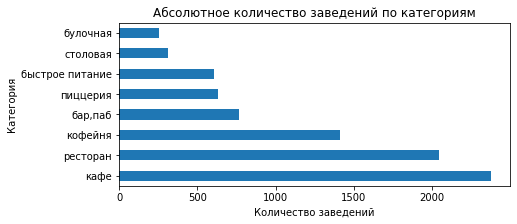

In [31]:
plt.figure(figsize=(7, 3))

df["category"].value_counts().plot(kind="barh", x="category", legend=False, title="Абсолютное количество заведений по категориям")
    
plt.xlabel('Количество заведений')
plt.ylabel('Категория')

plt.show()

Для определения доли на рынке, которую занимает тот или иной формат, построим диаграмму, отображающую относительное количество заведений разных категорий

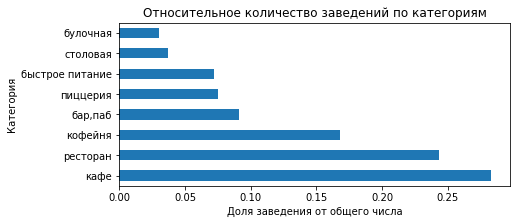

In [32]:
plt.figure(figsize=(7, 3))

df["category"].value_counts(normalize=True).plot(kind="barh", x="category", legend=False, title="Относительное количество заведений по категориям")
    
plt.xlabel('Доля заведения от общего числа')
plt.ylabel('Категория')

plt.show()

Самой популярной категорией заведения общественного питания является `кафе`(2378 точек). `Кафе` занимает 28% рынка, в то время как `булочные`только 3%. В топ-3 форматов заведений также входят `рестораны`(2043 точки и 24% рынка) и `кофейни`(1413 точек и 17% рынка)

---

### Распределение точек разных форматов в разрезе округа расположения

Изучим, какие административные районы Москвы присутствуют в данных. Исследуем распределение количества заведений по административным районам Москвы, а также отдельно распределение заведений каждой категории в Центральном административном округе Москвы. Результат сопроводим подходящими визуализациями.

Заменим длинные названия административных округов на аббревиатуры для удобства чтения графика

In [33]:
district_abbrev = {'Центральный административный округ': 'ЦАО',
    'Северный административный округ': 'САО',
    'Северо-Восточный административный округ': 'СВАО',
    'Восточный административный округ': 'ВАО',
    'Юго-Восточный административный округ': 'ЮВАО',
    'Южный административный округ': 'ЮАО',
    'Юго-Западный административный округ': 'ЮЗАО',
    'Западный административный округ': 'ЗАО',
    'Северо-Западный административный округ': 'СЗАО'}
df['district_short'] = df['district'].map(district_abbrev)

Рассчитаем количество заведений по административным округам с помощью метода `value_counts()`

In [34]:
df["district_short"].value_counts()

ЦАО     2242
САО      900
ЮАО      892
СВАО     891
ЗАО      851
ВАО      798
ЮВАО     714
ЮЗАО     709
СЗАО     409
Name: district_short, dtype: int64

In [35]:
round(df["district_short"].value_counts()/df.shape[0],2)

ЦАО     0.27
САО     0.11
ЮАО     0.11
СВАО    0.11
ЗАО     0.10
ВАО     0.09
ЮВАО    0.08
ЮЗАО    0.08
СЗАО    0.05
Name: district_short, dtype: float64

Построим график распределения абсолютного количества заведений по округам

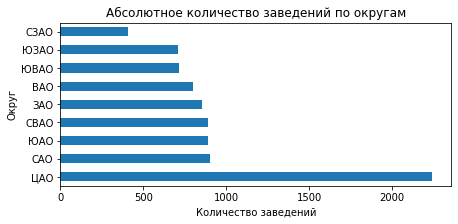

In [36]:
plt.figure(figsize=(7, 3))

df["district_short"].value_counts().plot(kind="barh", x="category", legend=False, title="Абсолютное количество заведений по округам")
    
plt.xlabel('Количество заведений')
plt.ylabel('Округ')

plt.show()

Построим график распределения относительного количества заведений по округам

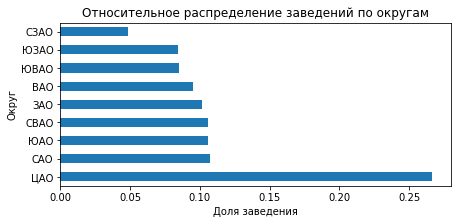

In [37]:
plt.figure(figsize=(7, 3))

df["district_short"].value_counts(normalize=True).plot(kind="barh", x="category", legend=False, title="Относительное распределение заведений по округам")
    
plt.xlabel('Доля заведения')
plt.ylabel('Округ')

plt.show()

Количество состредоточено неравномерно: самая высокая плотность заведений наблюдается в центральном административном округе (насчитывает 2242 заведения). На СЗАО приходится меньше всего заведений (409), что на 300 заведений меньше округа, занимающего строчку выше (ЮЗАО 709 заведений).

Определим, как распределено количество заведений по категориям в Москве (по данным всех административных округов)

In [38]:
df["category"].value_counts()

кафе               2378
ресторан           2043
кофейня            1413
бар,паб             765
пиццерия            633
быстрое питание     603
столовая            315
булочная            256
Name: category, dtype: int64

In [39]:
round(df["category"].value_counts()/df.shape[0],2)

кафе               0.28
ресторан           0.24
кофейня            0.17
бар,паб            0.09
пиццерия           0.08
быстрое питание    0.07
столовая           0.04
булочная           0.03
Name: category, dtype: float64

Построим график распределения количества заведений по категориям в Москве

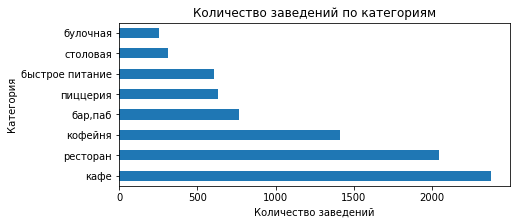

In [40]:
plt.figure(figsize=(7, 3))

df["category"].value_counts().plot(kind="barh", x="category", legend=False, title="Количество заведений по категориям")
    
plt.xlabel('Количество заведений')
plt.ylabel('Категория')

plt.show()

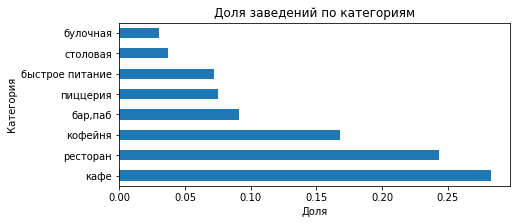

In [41]:
plt.figure(figsize=(7, 3))

df["category"].value_counts(normalize=True).plot(kind="barh", x="category", legend=False, title="Доля заведений по категориям")
    
plt.xlabel('Доля')
plt.ylabel('Категория')

plt.show()

Оказалось, что количество заведений категории `кафе` превышает остальные форматы (2378 точек). Следующей категорий по количеству открытых предприятий является `ресторан`(2043), тройку лидеров замыкает `кофейня` (1413 точек или 17% рынка).

Подробнее изучим распределение количества заведений по категориям в ЦАО

Отфильтруем датафрейм и оставим только данные по ЦАО

In [42]:
df_filtered = df[df["district_short"] == "ЦАО"]

Определим абсолбтное и относительное количество заведений в разрезе категорий в ЦАО Москвы. Данные представим в виде таблиц, а также визуализируем результаты с помощью диаграмм.

In [43]:
df_filtered["category"].value_counts()

ресторан           670
кафе               464
кофейня            428
бар,паб            364
пиццерия           113
быстрое питание     87
столовая            66
булочная            50
Name: category, dtype: int64

In [44]:
round(df_filtered["category"].value_counts()/df_filtered.shape[0],2)

ресторан           0.30
кафе               0.21
кофейня            0.19
бар,паб            0.16
пиццерия           0.05
быстрое питание    0.04
столовая           0.03
булочная           0.02
Name: category, dtype: float64

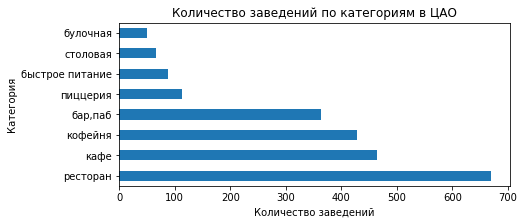

In [45]:
plt.figure(figsize=(7, 3))

df_filtered["category"].value_counts().plot(kind="barh", x="category", legend=False, title="Количество заведений по категориям в ЦАО")
    
plt.xlabel('Количество заведений')
plt.ylabel('Категория')

plt.show()

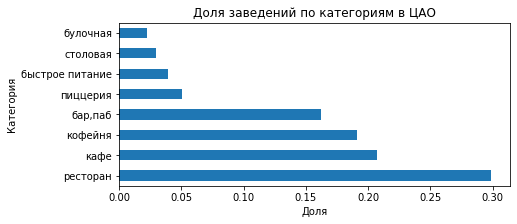

In [46]:
plt.figure(figsize=(7, 3))

df_filtered["category"].value_counts(normalize=True).plot(kind="barh", x="category", legend=False, title="Доля заведений по категориям в ЦАО")
    
plt.xlabel('Доля')
plt.ylabel('Категория')

plt.show()

Определим, какая доля заведений определенной категории от общего количества распологается в ЦАО

In [47]:
round(df_filtered["category"].value_counts()/df["category"].value_counts(),2)

бар,паб            0.48
булочная           0.20
быстрое питание    0.14
кафе               0.20
кофейня            0.30
пиццерия           0.18
ресторан           0.33
столовая           0.21
Name: category, dtype: float64

48% заведений категории `бар, паб` сосредоточено в ЦАО. 

Определим, какая доля заведений определенной категории от общего количества распологается в СЗАО

In [48]:
df_csao = df[df["district_short"] == "СЗАО"]

In [49]:
round(df_csao["category"].value_counts()/df["category"].value_counts(),2)

бар,паб            0.03
булочная           0.05
быстрое питание    0.05
кафе               0.05
кофейня            0.04
пиццерия           0.06
ресторан           0.05
столовая           0.06
Name: category, dtype: float64

In [50]:
df_usao = df[df["district_short"] == "ЮЗАО"]

In [51]:
round(df_usao["category"].value_counts()/df["category"].value_counts(),2)

бар,паб            0.05
булочная           0.11
быстрое питание    0.10
кафе               0.10
кофейня            0.07
пиццерия           0.10
ресторан           0.08
столовая           0.05
Name: category, dtype: float64

Распределение заведений по категориям в ЦАО отличается от общего распределения количества заведений по категориям в Москве.
Количество ресторанов превышает количество кафе на 9%, когда как по городу количество кафе выше на 4%. На третьем месте стабильно распологаются кофейни, но их количество в ЦАО занимает большую долю, чем по городу. Остальное распределение совпадает с распределением по городу: количество булочных остается наименьшим.

---

### Распределение сетевых и несетевых заведений

Изучим соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения. Определим, сетевых или несетевых заведений больше. Узнаем, заведение какого формата чаще является сетевым. Результат сопроводим подходящими графиками.

In [52]:
df['chain'].value_counts()

0    5201
1    3205
Name: chain, dtype: int64

In [53]:
round(df['chain'].value_counts()/df.shape[0],2)

0    0.62
1    0.38
Name: chain, dtype: float64

Количество несетевых заведений занимает большую часть рынка общественного питания (62%), количество сетевых заведений составляет 38%

Построим диаграмму, отражающую распределение доли сетевых заведений различных категорий

In [54]:
df_chain_category = df.groupby('category')["chain"].agg("mean").sort_values(ascending=False)

In [55]:
df_chain_category

category
булочная           0.613281
пиццерия           0.521327
кофейня            0.509554
быстрое питание    0.384743
ресторан           0.357318
кафе               0.327586
столовая           0.279365
бар,паб            0.220915
Name: chain, dtype: float64

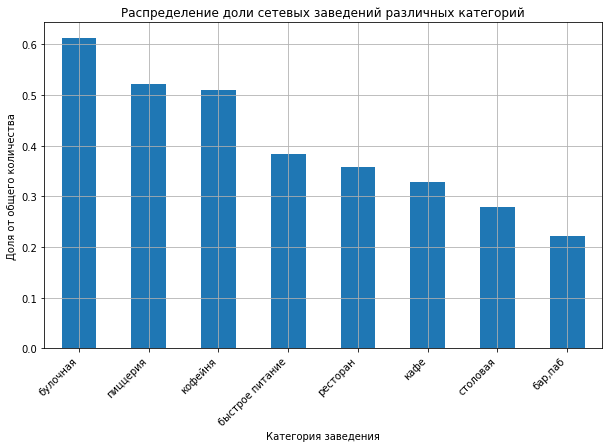

In [56]:
plt.figure(figsize=(10, 6))
df_chain_category.plot(kind="bar", grid=True)
plt.title("Распределение доли сетевых заведений различных категорий")
plt.xlabel("Категория заведения")
plt.ylabel("Доля от общего количества")
plt.xticks(rotation=45, ha='right') 
plt.show()

Формат заведений `Булочная` является лидером по доли сетевых заведений, более 60% точек являются сетевыми. Пиццерии и кофейни более чем в половине случаев принадлежат сети (52% и 51% соответственно - сетевые заведения). Бары и пабы являются сетевыми заведениями лишь в 22% случаев. 


---

### Исследование посадочных мест в заведениях

Исследуем количество посадочных мест в заведениях. Определим, встречаются ли в данных аномальные значения или выбросы и причину, по которой они могли появиться в данных. Приведем для каждой категории заведений наиболее типичное для него количество посадочных мест. Результат сопроводим подходящими визуализациями.


In [57]:
df['seats'].median()

75.0

In [58]:
df.groupby('category')['seats'].agg(["median", "min", "max"])

,median,min,max
category,,,
"бар,паб",82.5,0.0,1288.0
булочная,50.0,0.0,625.0
быстрое питание,65.0,0.0,1040.0
кафе,60.0,0.0,1288.0
кофейня,80.0,0.0,1288.0
пиццерия,55.0,0.0,1288.0
ресторан,86.0,0.0,1288.0
столовая,75.5,0.0,1200.0


Построим гистограмму распределения количества посадочных мест и диаграмму размаха

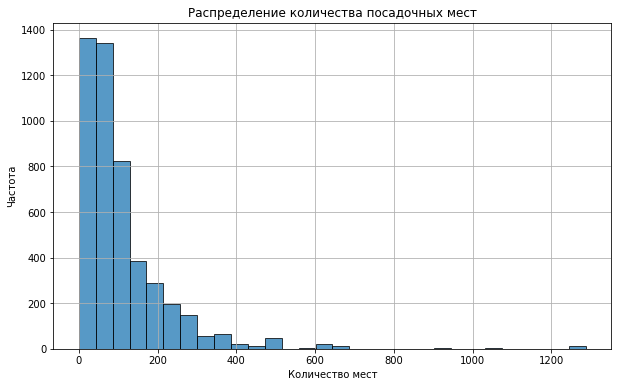

In [59]:
plt.figure(figsize=(10, 6))
df['seats'].plot(
                kind='hist', 
                bins=30,
                alpha=0.75,
                edgecolor='black',
                rot=0,
)
plt.title('Распределение количества посадочных мест')
plt.xlabel('Количество мест')
plt.ylabel('Частота')
plt.grid()

plt.show()

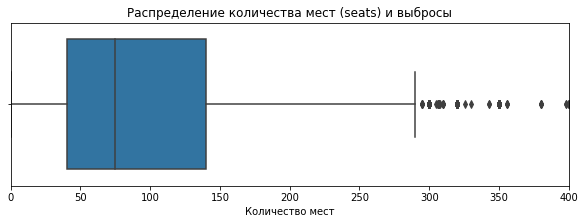

In [60]:
plt.figure(figsize=(10, 3))
sns.boxplot(data=df, x='seats')
plt.xlim(0, 400) 
plt.title('Распределение количества мест (seats) и выбросы')
plt.xlabel('Количество мест')
plt.show()

Добавим точный расчет квартилей

In [61]:
df['seats'].quantile([0.25, 0.5, 0.75])

0.25     40.0
0.50     75.0
0.75    140.0
Name: seats, dtype: float64

Первый квартиль равен 40, третий квартиль принимает значение 140, второй квартиль - 75. Границы усов показывают значения без выбросов. При этом мы наблюдаем аномальные значения посадочных мест во всех категориях. Причины их появления: в данных есть информация о местах в банкетных залах, количество посадочных мест действительно может достигать таких значений. Помимо этого, для некоторых сетевых заведений могли указать количество посадочных мест по сети, а не для одной конкретной точки (мы склоняемся к этому варианту, потому что аномальные значения встречаются в каждой категории). Также это может быть связано с ошибкой парсинга. При этом значение посадочных мест, равное 0, объясняется форматом - заведение может работать навынос.

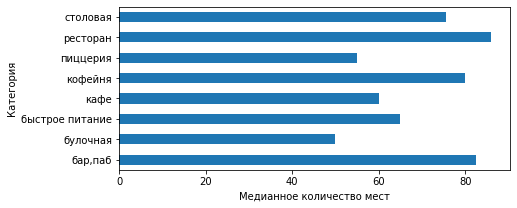

In [62]:
plt.figure(figsize=(7, 3))
agg_df = df.groupby('category')['seats'].median()
agg_df.plot(kind='barh')

plt.xlabel('Медианное количество мест')
plt.ylabel('Категория')
plt.show()

Медианное значение посадочных мест всех форматов превышает 40. В ресторане чаще всего больше посадочных мест, чем в заведениях других форматов, а в булочной меньше.

---

### Исследования рейтинга заведений в разрезе формата

Исследуем рейтинг заведений. Визуализируем распределение средних рейтингов по категориям заведений. Определим, сильно ли различаются усреднённые рейтинги для разных типов общепита.

Сгруппируем данные и найдем медианное значение рейтинга для каждой категории

In [63]:
df_rating = df.groupby('category')['rating'].agg("median").sort_values(ascending=False)

In [64]:
df_rating

category
бар,паб            4.4
булочная           4.3
кофейня            4.3
пиццерия           4.3
ресторан           4.3
столовая           4.3
быстрое питание    4.2
кафе               4.2
Name: rating, dtype: float32

Заметим, что рейтинг каждой категории выше 4 баллов, чтобы разница в распределении рейтинга была более явной, ограничим ось x при построении графика.

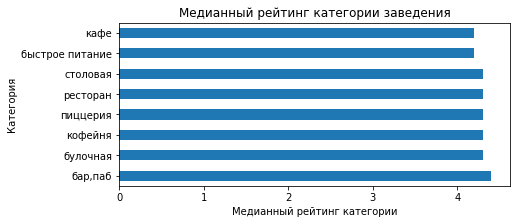

In [65]:
plt.figure(figsize=(7, 3))
df_rating.plot(kind='barh')
plt.title("Медианный рейтинг категории заведения")
plt.xlabel('Медианный рейтинг категории')
plt.ylabel('Категория')
plt.show()

Наибольший медианный рейтинг наблюдается в категорияи `бар и паб`(4.4 балла). `Быстрое питание` и `кафе` имеют равный медианный рейтинг - 4.2 балла, тем самым уступают лидеру 0.2 балла. Заведения остальных категорий имеют медианный рейтинг 4.3 балла.

---

### Какие данные о заведении коррелируют с его рейтингом

Изучим, с какими данными показывают самую сильную корреляцию рейтинги заведений. Построим и визуализируем матрицу корреляции рейтинга заведения с разными данными: его категория, положение (административный район Москвы), статус сетевого заведения, количество мест, ценовая категория и признак, является ли заведения круглосуточным. Выберем самую сильную связь и проверим её.

In [66]:
df_corr = df[['district_short', 'category', 'is_24_7', 'chain', 'seats', 'price', 'rating']].copy()
df_corr['is_24_7'] = df_corr['is_24_7'].astype(int)
numeric_cols = ['seats', 'rating', 'is_24_7'] 

correlation_matrix = df_corr.phik_matrix(interval_cols=numeric_cols)
print('Корреляционная матрица с коэффициентом phi_k для переменной rating')
rating_corr = correlation_matrix.loc[correlation_matrix.index != 'rating', ['rating']].sort_values(by='rating', ascending=False)
display(rating_corr)

Корреляционная матрица с коэффициентом phi_k для переменной rating


,rating
price,0.262056
category,0.198949
district_short,0.189389
is_24_7,0.160804
chain,0.119071
seats,0.000000


Наибольшая корреляция с рейтингом наблюдается с ценовой категорией заведения, `price`, значение составляет **0,26**. Помимо этого наблюдаем корреляцию с категорией заведения, остальные значения варируются от 0,20 до 0. Важно помнить, что показатель лишь говорит о существующей связи, а не о ее причинах, исследуем зависимость более подробно, а перед этим отобразим результаты с помощью тепловой карты и библиотеки sesborn

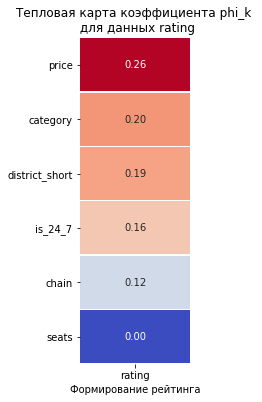

In [67]:
plt.figure(figsize=(2, 6))
data_heatmap = correlation_matrix.loc[correlation_matrix.index != 'rating'][['rating']].sort_values(by='rating', ascending=False)
sns.heatmap(data_heatmap,
            annot=True, 
            fmt='.2f',
            cmap='coolwarm', 
            linewidths=0.5, 
            cbar=False
           )

plt.title('Тепловая карта коэффициента phi_k для данных rating')
plt.xlabel('Формирование рейтинга')

plt.show()

Для проверки самой сильной связи построим диаграммы размаха и определим, как меняется средняя оценка заведения в зависимости от категории заведения.

In [68]:
grouped = df.groupby('price')['rating'].agg(["min", "max", "median"])

In [69]:
grouped

,min,max,median
price,,,
высокие,1.0,5.0,4.4
выше среднего,2.9,5.0,4.4
низкие,2.6,5.0,4.2
средние,1.6,5.0,4.3


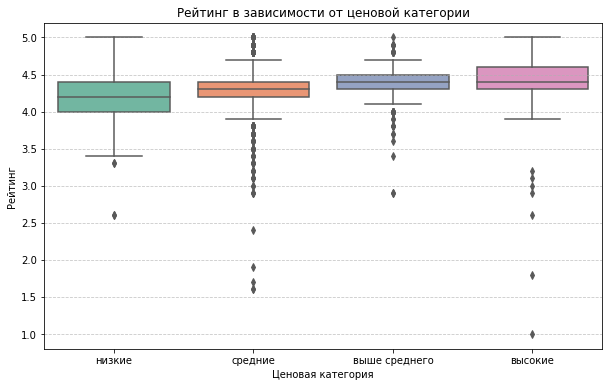

In [70]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='price', y='rating', 
            order=['низкие', 'средние', 'выше среднего', 'высокие'], 
            palette='Set2')

plt.title('Рейтинг в зависимости от ценовой категории')
plt.xlabel('Ценовая категория')
plt.ylabel('Рейтинг')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Медианная оценка категории `низкие` незначительно ниже медианного рейтинга других категорий, составляет 4,2 и отличается на 0,2 балла от лидеров категорий по медианной оценки (`высокие`, `выше среднего`). При этом именно в категории высоких цен наблюдается самый низкий рейтинг заведения - 1 балл. Таким образом, мы наблюдаем очень слабую связь между ценовой категорией заведения и его рейтингом. 

---

### Топ-15 популярных сетей Москвы

Сгруппируем данные по названиям заведений и найдем топ-15 популярных сетей в Москве. Для них посчитаем значения среднего рейтинга. Под популярностью будем понимать количество заведений этой сети в регионе. Помимо этого определим к какой категории заведений они относятся. Результат сопроводим подходящими визуализациями.

Определим самые популярные заведения, для этого сгруппируем данные по столбцу `name`, далее определим количество заведений с таким названием, отсортируем по убыванию количества заведений, выведем первые 15 элементов данных

In [71]:
df_chains = df[df["chain"] == 1]

In [72]:
top_15 = df_chains.groupby("name").size().sort_values(ascending=False).head(15)

In [73]:
top_15

name
шоколадница                            120
домино'с пицца                          76
додо пицца                              74
one price coffee                        71
яндекс лавка                            69
cofix                                   65
prime                                   50
хинкальная                              44
кофепорт                                42
кулинарная лавка братьев караваевых     39
теремок                                 38
чайхана                                 37
cofefest                                32
буханка                                 32
му-му                                   27
dtype: int64

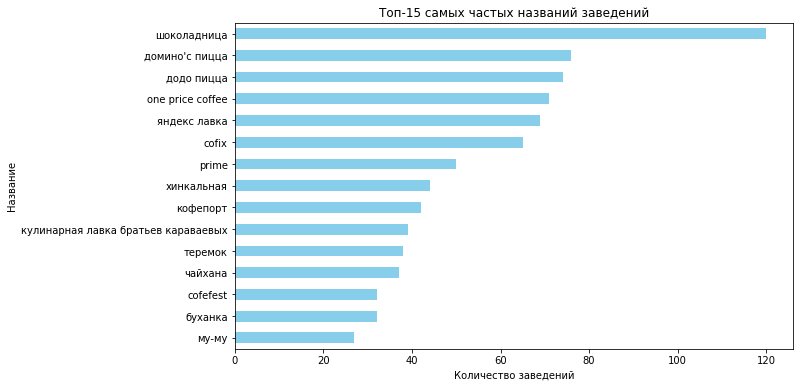

In [74]:
plt.figure(figsize=(10, 6))
top_15.plot(kind='barh', color='skyblue')

plt.xlabel('Количество заведений')
plt.ylabel('Название')
plt.title('Топ-15 самых частых названий заведений')
plt.gca().invert_yaxis() 
plt.show()

Наиболее популярными заведениями являются "Шоколадница", заведения с таким названием встречаются 120 раз, "Додо Пицца" и "Домино Пицца" упоминается более 74 и 76 раза соответственно. В конце рейтинга расположена сеть "Му-Му", она насчитывает 27 точек.

Далее определим средний рейтинг сети, сгруппировав данные по столбцу `name` с помощью groupby и агрегирования по второму квартилю

In [75]:
top_names = top_15.index
df_top15 = df[df["name"].isin(top_names)]
df_grouped = df_top15.groupby("name")["rating"].agg("median").sort_values(ascending=False)
print(df_grouped)

name
буханка                                4.40
кулинарная лавка братьев караваевых    4.40
хинкальная                             4.40
додо пицца                             4.30
му-му                                  4.30
one price coffee                       4.20
prime                                  4.20
домино'с пицца                         4.20
кофепорт                               4.20
шоколадница                            4.20
cofix                                  4.10
теремок                                4.10
чайхана                                4.10
cofefest                               4.05
яндекс лавка                           4.00
Name: rating, dtype: float32


Построим диаграмму распределения рейтинга по данным таблицы

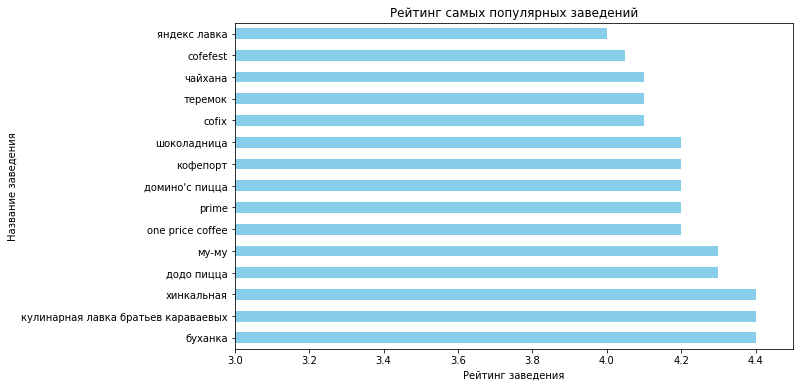

In [76]:
plt.figure(figsize=(10, 6))
df_grouped.plot(kind='barh', color='skyblue')
plt.title("Рейтинг самых популярных заведений")
plt.xlabel("Рейтинг заведения")
plt.xlim(3.0, 4.5)
plt.ylabel("Название заведения")
plt.show()

Рейтинг сетей находится в диапазоне от 4.0 балла до 4.40 баллов, в среднем, пользователи высоко оценивают точку сети. Наименьший рейтинг у заведения `Яндекс Лавка`, он составляет 4.0 балла. При этом стоит отметить, что данная сеть имеет 69 точек. Рейтинг заведений-лидеров по количеству торговых точек отличается от заведений-лидеров по оценкам пользователей незначительно: разница между рейтингом "Шоколадницы" и "Буханки" только 2 десятые балла, можно сказать, что таким сетям удается сохранять стандарты качества при большом количестве точек 

In [77]:
unique_combinations = df_top15[["name", "category"]].drop_duplicates()
print(unique_combinations)

                                     name         category
13                                буханка         булочная
32                             додо пицца         пиццерия
34                         домино'с пицца         пиццерия
46                               cofefest          кофейня
52                                  cofix          кофейня
80                                  му-му             кафе
107                               теремок         ресторан
109                               чайхана             кафе
138                            хинкальная  быстрое питание
143                      one price coffee          кофейня
151                           шоколадница          кофейня
162                          яндекс лавка         ресторан
394                               чайхана  быстрое питание
512                           шоколадница             кафе
548                              кофепорт          кофейня
872                               буханка          кофей

Также мы веделили категории, к которым относятся данные заведения. Самая популярная сеть заведений `Шоколадница` относится к кофейням, "Додо Пицца" и "Домино'с Пицца" относятся к пиццериям

---

### Вариация среднего чека в разрезе округа



Изучим вариацию среднего чека заведения (столбец `middle_avg_bill`) в зависимости от района Москвы. Проанализируем цены в Центральном административном округе и других. Определим как удалённость от центра влияет на цены в заведениях. Результат сопроводим подходящими визуализациями.


In [78]:
print(df['middle_avg_bill'].describe())

count     3149.000000
mean       958.053668
std       1009.732845
min          0.000000
25%        375.000000
50%        750.000000
75%       1250.000000
max      35000.000000
Name: middle_avg_bill, dtype: float64


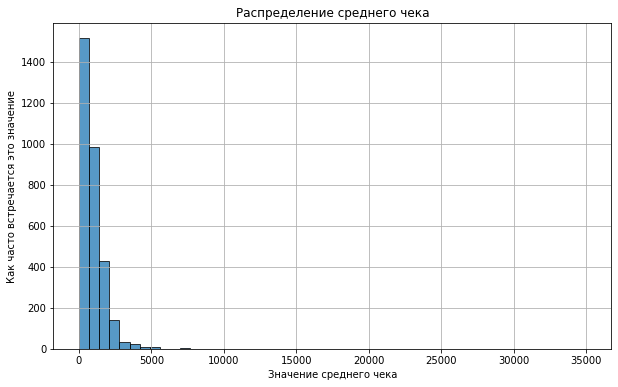

In [79]:
plt.figure(figsize=(10, 6))
df['middle_avg_bill'].plot(
                kind='hist', 
                bins=50,
                alpha=0.75,
                edgecolor='black',
                rot=0
)
plt.title('Распределение среднего чека')
plt.xlabel('Значение среднего чека')
plt.ylabel('Как часто встречается это значение')
plt.grid()

plt.show()

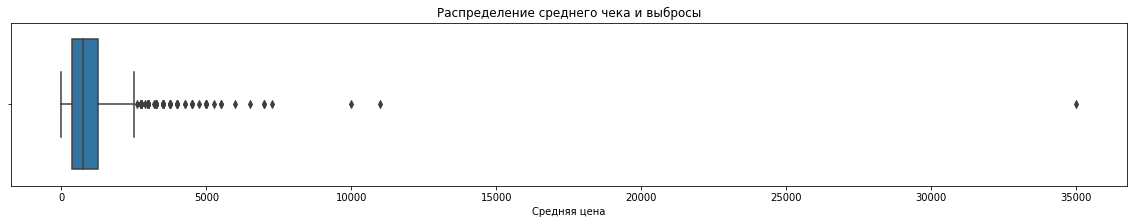

In [80]:
plt.figure(figsize=(20, 3))
sns.boxplot(data=df, x='middle_avg_bill') 
plt.title('Распределение среднего чека и выбросы')
plt.xlabel('Средняя цена')
plt.show()

Анализ показал, что медианный средний чек (50-й процентиль) составляет 750 рублей, а половина всех заведений имеет чек в диапазоне от 375 до 1250 рублей. При этом среднее арифметическое значение (958 руб.) значительно выше медианы, что указывает на сильную правостороннюю асимметрию распределения: основная масса заведений имеет невысокие чеки, но присутствуют аномально крупные значения (например, 35000 рублей). Аномально большее значение не похоже на ошибку, так как заведение действительно можн иметь такой чек.

In [81]:
df_bill = df.groupby("district_short")["middle_avg_bill"].agg("median").sort_values(ascending=False)

In [82]:
df_bill

district_short
ЗАО     1000.0
ЦАО     1000.0
СЗАО     700.0
САО      650.0
ЮЗАО     600.0
ВАО      575.0
СВАО     500.0
ЮАО      500.0
ЮВАО     450.0
Name: middle_avg_bill, dtype: float64

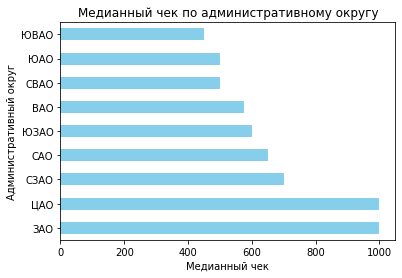

In [83]:
df_bill.plot(kind='barh', color='skyblue')
plt.title("Медианный чек по административному округу")
plt.xlabel("Медианный чек")
plt.ylabel("Административный округ")
plt.show()

Анализ медианного среднего чека (middle_avg_bill) показал, что стоимость посещения заведений в Москве существенно различается в зависимости от административного округа. Самые высокие цены зафиксированы в ЦАО (1000 руб.) и ЗАО (1000 руб.). Самые низкие цены — в ЮВАО (450 руб.), а также в СВАО (500 руб.) и ЮАО (500 руб.). Разница между самым дорогим и самым дешевым округом составляет более чем в 2 раза (1000 руб. против 450 руб.), что говорит о сильной дифференциации рынка. Таким образом, удаленность от центра является важным, но не единственным фактором, влияющим на цену.

Построим диаграммы размаха для каждого административного округа Москвы

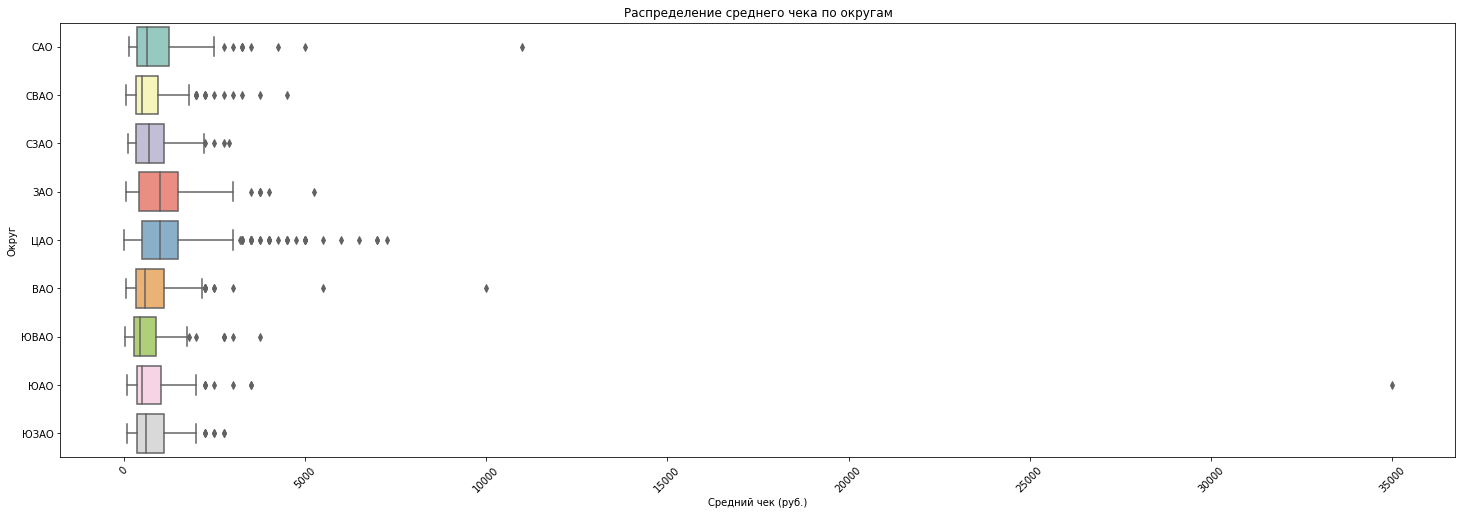

In [84]:
plt.figure(figsize=(25, 8))
sns.boxplot(data=df, y='district_short', x='middle_avg_bill', palette='Set3')
plt.title('Распределение среднего чека по округам')
plt.xlabel('Средний чек (руб.)')
plt.ylabel('Округ')
plt.xticks(rotation=45)
plt.show()

Анализ распределения среднего чека по округам Москвы, представленный на диаграмме размаха, подтверждает и дополняет ранее сделанные выводы. На графике отчетливо видно, что самые высокие медианные значения среднего чека зафиксированы в Западном (ЗАО) и Центральном (ЦАО) административных округах. Также высокий медианный чек наблюдается в Северо-Западном округе (СЗАО) и составляет 700 рублей. В то же время самые низкие медианные показатели характерны для ЮВАО (450 рублей), ЮАО (500 рублей) и СВАО (500 рублей). Важно отметить, что во всех округах наблюдается значительный разброс цен. При этом самый большой разброс характерен для ВАО и САО: на диаграмме размаха видим аномальные значения, выходящие за границы усов

---

### Промежуточный вывод

Обобщим полученные результаты, выделив самые важные.

В ходе исследовательского анализа мы:
- Выяснили, заведения каких категорий представлены в данных. Для этого нашли абсолютные и относительные значения. Пришли к выводам, что самой популярной категорией заведения общественного питания является `кафе`(2378 точек или 28% рынка). Менее популярной - `булочная`. В топ-3 форматов заведений также входят `рестораны`(2043 точки или 24% рынка общественного питания) и `кофейни`(1413 точек или 17% рынка)
- Исследовали распределение количества заведений по административным районам Москвы, а также отдельно распределение заведений каждой категории в Центральном административном округе Москвы. Определили абсолютного лидера по количеству заведений - `ЦАО`(2242 заведения), данный округ занимает более четверти рынка. Количество заведений `ЦАО` на 1342 превышает округ, занимающий вторую позицию - `САО` (900 заведений). Далее рассмотрели распределение количества заведений по всем округам и в `ЦАО`. Выяснили, что доля ресторанов в `ЦАО` выше, чем по городу.
- Изучили соотношение сетевых и несетевых заведений. Выяснили, что сетевые заведения занимают 38% рынка. Выяснили, что булочные являются лидерами по соотношению сетевых заведений к несетевым (60% булочных являются точками сети) 
- Исследовали количество посадочных мест в заведениях. Выяснили, что медианное количество мест в заведении - 75. Категория-лидер по медианному значению посадочных мест `ресторан`- 86 мест. Обнаружили аномальные значения в данных. Предположили возможные причины появления (указано количество мест для сети, а не конкретной точки, заведение работает только навынос, возникли ошибки при парсинге)
- Исследовали медианный рейтинг заведений в разрезе категорий. Выяснили, что рейтинг лежит в диапазоне от 4.2 до 4.4 балла. `Бары, пабы` являются лидерами рейтинга, медианный рейтинг категории - 4.4. На последнем месте расположились `кафе` и рестораны `быстрого питания`, однако рейтинг в этих категориях отличается от топ-1 на 0.2 балла. Рейтинг категорий отличается незначительно
- Изучили с какими данными имеет корреляцию рейтинг заведения. Наибольший коэффициент корреляции наблюдался с ценовой категорией заведения. С помощью диаграмм размаха мы определили, что у заведений с `низкой` ценовой категорией медианный рейтинг меньше, но разница незначительно, поэтому **связь** между ценовой категорией и рейтингом заведения **выражена слабо**
- Определили топ-15 сетей по количеству точек в Москве. Лидерами стали `Шоколадница` (120 точек, категория `кофейня`), `Домино'с Пицца` (76 заведений, категория `пиццерия`) и `Додо Пицца` (74, `пиццерия`)
- Исследовали распределение среднего чека и медианное значение среднего чека в разрезе районов. Анализ показал, что медианный средний чек (50-й процентиль) составляет 750 рублей, а половина всех заведений имеет чек в диапазоне от 375 до 1250 рублей. Наибольший средний чек наблюдается в ЦАО и ЗАО

## Итоговый вывод и рекомендации

По результатам проведённого исследовательского анализа данных сформулируем итоговый вывод и рекомендации для заказчика. При этом будем акцентировать внимание на ключевых моментах исследования.

Построим вывод по следующей структуре:
1. Общий обзор проделанной работы.
2. Ответы на исследовательские вопросы (главные выводы).
3. Рекомендации на основе анализа данных.

### Общий обзор проделанной работы

#### Познакомились с данными
- **Выгрузили данные** датасетов `rest_info.csv` с информацией о заведениях общественного питания и `rest_price.csv` с информацию о среднем чеке в заведениях общественного питания
- Выяснили, что датасеты **имеют размеры** 8406 строк на 9 столбцов и 4058 строк на 5 столбцов соответственно
- Выяснили, что первый датафрейм **содержит пропуски в столбцах `hours` и `seats`**. Определили возможную причину возникновения пропусков: заведение работает навынос, поэтому в столбце `seats` не указано количество посадочных мест. 
- Второй датафрейм **содержит пропуски во всех столбцах**, **кроме столбца `id`**. Предположили, что пропуски могут быть связаны с неполной информацией в Яндекс Картах и Яндекс Бизнесе, не все заведения могут размещать актуальную информацию на этих платформах. Помимо этого неполные данные могут быть связаны с спецификой столбца - значения столбцов `middle_avg_bill` и `middle_coffee_cup` содержат значения строк, имеющих подстроку "средний счет" или "Цена одной чашки капучино", а такие данные могут отсутстововать в некоторых форматах заведений
- Объединили два датафрейма с помощью метода "left", чтобы сохранить информацию о заведениях из первого датафрейма, для которых не указана средняя цена. В результате получился **новый датафрейм `df`**

#### Предобработали данные
- Провели оптимизацию данных в столбцах `rating` и `chain`
- Нашли абсолютное и относительное **количество пропусков** в столбцах датафрейма, разобрали возможные причины появления пропусков и приняли решение **не обрабатывать данные**, так как замена пропущенных значений значениями индикаторами или средними значениями может исказить анализ
- Добавили категориальный столбец `is_24_7`, чтобы проверить, является ли заведение круглосуточным.
- Поработали с дубликатами: в данных не оказалось явных дубликатов, но после нормализации значений столбцов `name` и `address` выяснилось, что в датасете встречаются заведения с одинаковым названием, расположенные по одному адресу. Мы решили не удалять строки дубликаты, потому что заметили, что у них различаются часы работы. Это можно связать с летним и зимним режимами работы или обновлением информации

### Главные выводы
- Распределение заведений по категориям. Наиболее популярной категорией является `кафе`(занимает 28% рынка), реже всего встречаются `булочные` - 3% рынка общественного питания Москвы
- Распределение точек разных форматов в разрезе округа: более четверти заведений распологаются в ЦАО, наименьшее количество заведений в СЗАО (5% заведений общественного питания от общего количества). Самым популярным форматом заведения в ЦАО является `ресторан`, `булочные` встречаются реже всего - 2% заведений общественного питания ЦАО, что составляет 20% всех заведений формата
- Соотношение сетевых и несетевых заведений: Сетевые заведения занимают 38% рынка и булочные являются лидерами по принадлежности к сети(60% являются сетевыми)
- Количество посадочных мест в заведении: медианное значение - 75, встречаются данные о заведениях с нулевым количеством мест(можно обосновать тем, что заведение работает навынос). Медианное значение посадочных мест категории `ресторан` самое высокое, самое низкое у `булочных`
- Изучили, с какими данными коррелирует рейтинг заведения. Наибольший коэффициент корреляции (по методу Phi_K) наблюдался с ценовой категорией заведения. С помощью диаграмм размаха (boxplot) мы определили, что у заведений с низкой ценовой категорией медианный рейтинг меньше, но разница незначительна. Таким образом, связь между ценовой категорией и рейтингом заведения выражена слабо.
- Определили топ-15 сетей по количеству точек в Москве. Лидерами стали Шоколадница (120 точек, категория кофейня), Домино'с Пицца (76 заведений, пиццерия) и Додо Пицца (74, пиццерия).
- Исследовали распределение среднего чека и медианное значение в разрезе районов. Анализ показал, что медианный средний чек (50-й процентиль) составляет 750 рублей, а половина всех заведений имеет чек в диапазоне от 375 до 1250 рублей. Наибольший средний чек наблюдается в ЦАО и ЗАО.

### Рекомендации

#### Выбор формата и ценовой категории


Учитывая, что рейтинг заведений в Москве стабильно высок (4.2–4.4) и практически не зависит от ценовой категории, **не стоит делать ставку на демпинг или, наоборот, на завышение цен в расчете на то, что это автоматически повысит оценку.** Связь между ценой и рейтингом слабая.

**Формат:** Рекомендуется открывать демократичное заведение **(кафе или кофейню).** Кафе — самая популярная категория (28% рынка), что гарантирует высокий спрос и широкую аудиторию. При этом сетевые кафе и кофейни занимают значительную долю, но у одиночных заведений есть пространство для маневра за счет уникальности.

**Ценовая категория:** Рекомендуется ориентироваться на средний ценовой сегмент. Согласно данным, медианный чек для категории «кафе» в этом сегменте составляет **586 рублей.**

In [85]:
round(df[(df["category"] == "кафе") & (df["price"] == "средние")]["middle_avg_bill"].mean())

586

#### Выбор локации (округа)
География Москвы крайне неоднородна. Если вы хотите открыть заведение с высоким средним чеком, ваш выбор — это **Центральный (ЦАО)** или **Западный (ЗАО)** административные округа. В них зафиксирован наибольший медианный средний чек (1000 рублей). Помимо этого стоит учитывать насыщенность рынка. В ЦАО находится 27% заведений общественного питания Москвы, когда как в ЗАО - 10%. Количество заведений данных округов отличается более чем в 2,5 раза (2242 заведения в ЦАО и 851 заведение в ЗАО)

####  Вместимость заведения
Медианное количество посадочных мест в Москве составляет 75. При этом рестораны имеют самую большую вместимость, а булочные — самую низкую.

Целесообразно ориентироваться на проектную вместимость в диапазоне от 50 до 80 посадочных мест. Данный диапазон представляет собой оптимальный баланс между операционной пропускной способностью и издержками. С одной стороны, он обеспечивает достаточную capacity для обслуживания пиковых нагрузок (обеденные часы, выходные дни) и максимизации выручки. С другой стороны, данная вместимость позволяет сохранять контроль над постоянными расходами (аренда, фонд оплаты труда) и минимизировать финансовые риски в периоды снижения потребительского трафика, не создавая избыточной нагрузки на операционную модель заведения.

#### Итоговая рекомендация 
Оптимальной стратегией для открытия новой точки является запуск заведения в формате кафе с проектной вместимостью 50–80 посадочных мест, позиционируемого в среднем ценовом сегменте, с приоритетной локацией в Западном административном округе (ЗАО). Данное сочетание параметров позволяет достичь сбалансированной бизнес-модели: обеспечить высокий уровень среднего чека за счет платежеспособной локальной аудитории, снизить уровень прямой конкуренции по сравнению с ЦАО, а также использовать наиболее востребованный рыночный формат, не требующий избыточных капиталовложений, характерных для премиального сегмента.
